<a href="https://colab.research.google.com/github/HamzaEric/online_retail_data_analytics/blob/main/Notebooks/data_quality_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [3]:
path_df_1 = Path("/content/drive/MyDrive/online_retail_data/online-retail-2009-2010.csv/online-retail-2009-2010.csv")
path_df_2 = Path("/content/drive/MyDrive/online_retail_data/online-retail-2010-2011.csv/online-retail-2010-2011.csv")

df_1 = pd.read_csv(path_df_1, parse_dates=["InvoiceDate"]).assign(source="2009-2010")
df_2 = pd.read_csv(path_df_2, parse_dates=["InvoiceDate"]).assign(source="2010-2011")

raw = pd.concat([df_1, df_2], ignore_index=True)

raw["Revenue"] = raw["Quantity"] * raw["Price"]

print(raw.shape)
print(f"raw revenue: £{raw['Revenue'].sum():,.0f}")

(1067371, 10)
raw revenue: £19,287,251


# Netting Cancelled Orders Out

In [4]:
once = raw.drop(columns="source").drop_duplicates()
products = once[once["StockCode"].str.match(r"\d{5}")]
is_cancel = products["Invoice"].str.startswith("C")

top_dropped = products[~is_cancel].groupby("Description")["Revenue"].sum().nlargest(3) / 1000
top_netted = products.groupby("Description")["Revenue"].sum().nlargest(3) / 1000

pd.DataFrame({
    "cancellations dropped": top_dropped.index, "£k (dropped)": top_dropped.round(1).values,
    "cancellations netted": top_netted.index, "£k (netted)": top_netted.round(1).values,
})

,cancellations dropped,£k (dropped),cancellations netted,£k (netted)
0,REGENCY CAKESTAND 3 TIER,330.6,REGENCY CAKESTAND 3 TIER,314.0
1,WHITE HANGING HEART T-LIGHT HOLDER,261.0,WHITE HANGING HEART T-LIGHT HOLDER,251.6
2,"PAPER CRAFT , LITTLE BIRDIE",168.5,PARTY BUNTING,147.1


> On 9 December 2011 a customer ordered **80,995** paper-craft birds, worth `£168,470`.
> Twelve minutes later the order was canceled: the file holds a second line for the same
> product with a quantity of −80,995. The product's name in the data is **PAPER CRAFT , LITTLE
> BIRDIE**, with that odd space before the comma.
>
> - **Dropping cancellations** removes the −80,995 line but keeps the order it canceled. The
>   birds are left with `£168.5k` of sales that never happened, enough for third place.
> - **Netting cancellations** keeps both lines, so they add up to zero: the birds have `£0` and
>   disappear from the ranking. Third place goes to the next real best seller, **PARTY
>   BUNTING**, with `£147.1k`.

## A Cleaning Log

- **Intuition.** A cleaning log is a lab notebook for data: one line per step, written *at the
  moment you take the step*, saying what you did, how many rows it touched and why.

In [5]:
def log_step(log, step, before, after, reason):
    """Record one cleaning step in `log` and return the cleaned table."""
    if step in [record["step"] for record in log]:
        raise ValueError(f"'{step}' is already in the log. To redo it, rerun the chain from `log = []`.")
    log.append({
        "step": step,
        "rows_before": len(before),
        "rows_after": len(after),
        "rows_removed": len(before) - len(after),
        "revenue_removed": round(before["Revenue"].sum() - after["Revenue"].sum()),
        "reason": reason,
    })
    return after


log = []

In [6]:
in_overlap = (raw["source"] == "2009-2010") & (raw["InvoiceDate"] >= "2010-12-01")

clean = log_step(log, "overlap between the exports", raw, raw[~in_overlap],
                 "1-9 Dec 2010 appears in both files; the 2010-2011 copy is kept")
print(f"{len(clean):,} lines")

1,044,848 lines


> 📊 **Reading the count.** **1,044,848** lines: 22,523 removed — exactly the nine days

In [7]:
clean = log_step(log, "repeated lines", clean, clean.drop_duplicates(),
                 "identical lines within a file, treated as double-recorded (judgment)")
print(f"{len(clean):,} lines")

1,033,036 lines


In [8]:
is_product = clean["StockCode"].str.match(r"\d{5}")

clean = log_step(log, "non-product codes", clean, clean[is_product],
                 "postage, fees and manual adjustments are not sales of products")
cleaning_log = pd.DataFrame(log)
cleaning_log[["step", "rows_before", "rows_after", "rows_removed", "revenue_removed"]]

,step,rows_before,rows_after,rows_removed,revenue_removed
0,overlap between the exports,1067371,1044848,22523,377488
1,repeated lines,1044848,1033036,11812,54228
2,non-product codes,1033036,1027056,5980,-70732


# Remove Or Flag Rows

In [9]:
clean = clean.assign(
    cancellation=clean["Invoice"].str.startswith("C"),
    stock_adjustment=clean["Price"] == 0,
    no_customer=clean["Customer ID"].isna(),
    partial_month=clean["InvoiceDate"] >= "2011-12-01",
)

flag_columns = ["cancellation", "stock_adjustment", "no_customer", "partial_month"]
flags = pd.DataFrame({
    "rows_flagged": clean[flag_columns].sum(),
    "share_of_rows": (clean[flag_columns].mean() * 100).round(1),
    "revenue_in_flagged_rows": [round(clean.loc[clean[c], "Revenue"].sum()) for c in flag_columns],
})
flags

,rows_flagged,share_of_rows,revenue_in_flagged_rows
cancellation,17914,1.7,-716426
stock_adjustment,5928,0.6,0
no_customer,232833,22.7,2567652
partial_month,25152,2.4,440396


> 📊 **Reading the flags.**
>
> - **17,914 cancellation lines** (1.7 %), carrying about `−£0.7M` of revenue — kept, so they
>   subtract from the orders they undo. Whether each one has an order to undo is checked below.
> - **5,928 lines at price 0**, often with no description at all (every line without a
>   description is one of them, as a validity check in section 4 confirms). Their revenue is
>   exactly `£0`, so keeping them changes no total. That they are stock adjustments is our
>   reading, also checked below.
> - **232,833 lines without a customer** — **22.7 %** of all lines, carrying **`£2.57M`** of
>   revenue. Sales totals are fine; any "per customer" figure would silently ignore more than a
>   fifth of the lines and `£2.57M` of sales.
> - **25,152 lines in December 2011** — nine days of a month.

> ⚠️ **Common mistake — dropping rows with missing values "to be safe".** `dropna()` here would
> delete 232,833 real sales and `£2.57M` of revenue from every total — the opposite of safe.
> Missing values in *one* column make a row unusable only for questions that need *that*
> column.

In [10]:
price_zero = clean[clean["stock_adjustment"]]

print(f"price-0 lines:       {len(price_zero):,}")
print(f"  no description:    {price_zero['Description'].isna().sum():,}")
print(f"  negative quantity: {(price_zero['Quantity'] < 0).sum():,}")
print(f"  with a customer:   {price_zero['Customer ID'].notna().sum():,}")
price_zero["Description"].value_counts().head(6)

price-0 lines:       5,928
  no description:    4,212
  negative quantity: 3,362
  with a customer:   60


,count
Description,
check,160
?,90
damages,83
damaged,81
found,28
missing,27


> 📊 **Reading the price-0 lines.** Of the **5,928** lines, **4,212** have no description,
> **3,362** have a negative quantity, and only **60** name a customer. The descriptions that
> do exist read like notes typed by staff — `check`, `?`, `damages`, `damaged`, `found`,
> `missing` — not like product names.

That is **evidence** for our reading: lines that move stock without a buyer or a price look
like internal corrections. It is not **proof**: the export has no column that says "stock
adjustment", and only the shop can confirm what its staff meant. So the report will say
*price-0 lines, which we read as stock adjustments*, and list the reading among its
limitations.

In [11]:
cancels = clean[clean["cancellation"]]
orders = clean[~clean["cancellation"]]

ordered = set(zip(orders["Customer ID"], orders["StockCode"]))
has_order = pd.Series([pair in ordered for pair in zip(cancels["Customer ID"], cancels["StockCode"])],
                      index=cancels.index)

print(f"cancellation lines:                       {len(cancels):,}")
print(f"  same customer ordered the same product: {has_order.sum():,} ({has_order.mean():.1%})")
print(f"  no such order in the data:              {(~has_order).sum():,}   revenue (£): {cancels.loc[~has_order, 'Revenue'].sum():,.0f}")

cancellation lines:                       17,914
  same customer ordered the same product: 16,552 (92.4%)
  no such order in the data:              1,362   revenue (£): -28,288


> 📊 **Reading the match.** **16,552** cancellation lines (**92.4 %**) have an order of the same
> product by the same customer somewhere in the data. The other **1,362** lines, carrying
> **`−£28,288`**, have none: 328 of them have no customer at all, and the rest presumably undo
> orders placed before the data starts. Their negative revenue is subtracted from sales that
> are not in our totals.

Even the matched 92.4 % are matched loosely: the test does not compare dates or quantities, so
it shows that an order *could* exist, not that the cancellation reverses it exactly. The
80,995-bird order of Lesson 4.2 is the clean case: same customer, same product, same quantity,
twelve minutes apart, netting to exactly `£0`. Most cancellations cannot be proven that
cleanly. **A cancellation guarantees net-zero sales only when its matching order is in the
data**

In [12]:
bulk = clean[clean["Quantity"].abs() >= 10_000]

print(f"{len(bulk)} lines")
bulk[["Invoice", "InvoiceDate", "Description", "Quantity", "Price", "Revenue", "Customer ID"]]

15 lines


,Invoice,InvoiceDate,Description,Quantity,Price,Revenue,Customer ID
90857,497946,2010-02-15 11:57:00,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902.0
127166,501534,2010-03-17 13:09:00,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,13902.0
127167,501534,2010-03-17 13:09:00,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,13902.0
127168,501534,2010-03-17 13:09:00,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,13902.0
127169,501534,2010-03-17 13:09:00,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,13902.0
135027,502269,2010-03-23 15:36:00,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0,17940.0
135028,502269,2010-03-23 15:36:00,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0,17940.0
135029,502269,2010-03-23 15:36:00,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0,17940.0
135030,502269,2010-03-23 15:36:00,PACK OF 12 WOODLAND TISSUES,10000,0.25,2500.0,17940.0
192197,507637,2010-05-10 14:55:00,FLAG OF ST GEORGE CAR FLAG,10200,0.00,0.0,NaN


## The Parts of a Data Quality Report

A basic data quality report answers five questions for someone who will use the data:

1. **Completeness** — how much of each column is filled in?
2. **Validity** — do the values obey the rules they should (no negative prices, dates in range)?
3. **Cleaning log** — what was removed or flagged, how much, why?
4. **Impact** — how different are the headline numbers before and after cleaning?
5. **Limitations** — what can this data *not* be used for?

In [13]:
completeness = clean.notna().mean()

(completeness * 100).round(1)

,0
Invoice,100.0
StockCode,100.0
Description,99.6
Quantity,100.0
InvoiceDate,100.0
Price,100.0
Customer ID,77.3
Country,100.0
source,100.0
Revenue,100.0


> 📊 **Reading completeness.** Every column is 100 % filled except two: `Description` (**99.6 %**
> — every missing description belongs to a price-0 line, as the next check confirms) and `Customer ID` (**77.3 %**). One number per column, and the
> reader knows immediately where the gaps are.

In [14]:
def failing_rows(table):
    """Count the rows of `table` that break each validity rule."""
    price_zero = table["Price"] == 0
    cancellation = table["Invoice"].str.startswith("C")
    dates = table["InvoiceDate"]
    return pd.Series({
        "quantity is never zero": (table["Quantity"] == 0).sum(),
        "price is never negative": (table["Price"] < 0).sum(),
        "negative quantities only on cancellations or price-0 lines":
            (~((table["Quantity"] > 0) | cancellation | price_zero)).sum(),
        "every date from 1 Dec 2009 to the end of 9 Dec 2011":
            (~((dates >= "2009-12-01") & (dates < "2011-12-10"))).sum(),
        "a description on every line with a price": (~(table["Description"].notna() | price_zero)).sum(),
    })


validity = pd.DataFrame({"failing rows (raw)": failing_rows(raw), "failing rows (clean)": failing_rows(clean)})
validity["passes"] = validity["failing rows (clean)"] == 0
validity

,failing rows (raw),failing rows (clean),passes
quantity is never zero,0,0,True
price is never negative,5,0,True
negative quantities only on cancellations or price-0 lines,0,0,True
every date from 1 Dec 2009 to the end of 9 Dec 2011,0,0,True
a description on every line with a price,0,0,True


> 📊 **Reading the checks.** All five rules pass on the cleaned data, with **0** failing rows
> each. That is the point of writing them: they are no longer assumptions but **checked facts**,
> and if a future export breaks one of them, the count will say how many rows did. The raw
> column shows that cleaning mattered: **5** raw lines had a negative price. A count invites
> the next question — *which lines?*

In [15]:
raw.loc[raw["Price"] < 0, ["Invoice", "StockCode", "Description", "Quantity", "Price"]]

,Invoice,StockCode,Description,Quantity,Price
179403,A506401,B,Adjust bad debt,1,-53594.36
276274,A516228,B,Adjust bad debt,1,-44031.79
403472,A528059,B,Adjust bad debt,1,-38925.87
825444,A563186,B,Adjust bad debt,1,-11062.06
825445,A563187,B,Adjust bad debt,1,-11062.06


> 📊 **Reading the examples.** Five accounting entries, `Adjust bad debt`, with stock code `B`
> and invoice numbers starting with `A`: money written off, not goods sold. Their code does
> not start with five digits

In [16]:
dec_2010 = lambda table: table.loc[table["InvoiceDate"].dt.to_period("M") == "2010-12", "Revenue"].sum()

headline = pd.DataFrame({
    "raw exports": [len(raw), raw["Revenue"].sum(), dec_2010(raw)],
    "after cleaning": [len(clean), clean["Revenue"].sum(), dec_2010(clean)],
}, index=["lines", "total revenue (£)", "December 2010 revenue (£)"])

headline.round(0)

,raw exports,after cleaning
lines,1067371.0,1027056.0
total revenue (£),19287251.0,18926266.0
December 2010 revenue (£),1126445.0,758024.0


In [17]:
after_overlap = raw[~in_overlap]
after_repeats = after_overlap.drop_duplicates()
after_products = after_repeats[after_repeats["StockCode"].str.match(r"\d{5}")]
steps = [raw, after_overlap, after_repeats, after_products]

pd.DataFrame({
    "revenue removed, all months (£)": cleaning_log["revenue_removed"].values,
    "revenue removed, December 2010 (£)": [round(dec_2010(before) - dec_2010(after))
                                          for before, after in zip(steps[:-1], steps[1:])],
}, index=cleaning_log["step"])

,"revenue removed, all months (£)","revenue removed, December 2010 (£)"
step,,
overlap between the exports,377488,377488
repeated lines,54228,2233
non-product codes,-70732,-11301


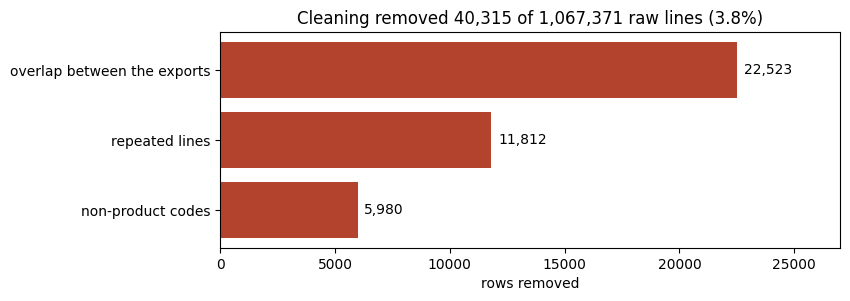

In [18]:
report_dir = Path("./report")
report_dir.mkdir(exist_ok=True)

fig_log, ax_log = plt.subplots(figsize=(8, 2.8))
ax_log.barh(cleaning_log["step"][::-1], cleaning_log["rows_removed"][::-1], color="#b4432e")
for position, value in enumerate(cleaning_log["rows_removed"][::-1]):
    ax_log.text(value + 300, position, f"{value:,}", va="center")
ax_log.set_xlabel("rows removed")
removed = cleaning_log["rows_removed"].sum()
ax_log.set_title(f"Cleaning removed {removed:,} of {len(raw):,} raw lines ({removed / len(raw):.1%})")
ax_log.set_xlim(0, 27000)
fig_log.savefig(report_dir / "cleaning-log.png", dpi=150, bbox_inches="tight")
plt.show()

# MD File

In [19]:
def markdown_table(table):
    """Turn a small DataFrame into the text of a Markdown table (index included)."""
    table = table.rename_axis(table.index.name or "").reset_index()
    header = "| " + " | ".join(str(column) for column in table.columns) + " |"
    rule = "|" + "---|" * len(table.columns)
    rows = ["| " + " | ".join(str(value) for value in row) + " |" for _, row in table.iterrows()]
    return "\n".join([header, rule] + rows)


print(markdown_table(flags))

|  | rows_flagged | share_of_rows | revenue_in_flagged_rows |
|---|---|---|---|
| cancellation | 17914 | 1.7 | -716426 |
| stock_adjustment | 5928 | 0.6 | 0 |
| no_customer | 232833 | 22.7 | 2567652 |
| partial_month | 25152 | 2.4 | 440396 |


In [20]:
filled = (completeness.drop(["source", "Revenue"] + flag_columns) * 100).round(1)

report = f"""# Data quality report — online retail sales, Dec 2009 – Dec 2011

Prepared by Brightside Insights from the two exports of the shop's sales workbook.

- Source: Online Retail II (Daqing Chen, UC Irvine Machine Learning Repository), delivered as `online-retail-2009-2010.csv.gz` and `online-retail-2010-2011.csv.gz`.
- Data as of: {raw["InvoiceDate"].max():%d %B %Y, %H:%M}, the last recorded line.
- Measure: net product-line revenue (Quantity x Price, in pounds, cancellations subtracted).

## 1. Completeness (% of values filled)
{markdown_table(filled.to_frame("filled %"))}

## 2. Validity checks (rows that break each rule)
{markdown_table(validity)}

The {validity.loc["price is never negative", "failing rows (raw)"]} raw lines with a negative price are "Adjust bad debt" entries (stock code B), removed as non-product codes.

## 3. Cleaning log
{markdown_table(cleaning_log.set_index("step"))}

Judgments behind the steps:
- Overlap: 1-9 Dec 2010 is in both files; the 2010-2011 copy is kept. The copies are identical, so the choice changes no number.
- Repeated lines: identical lines within a file are treated as double-recorded. The export has no line number to prove it.
- Non-product codes: a product is a stock code starting with five digits. Postage, fees, manual adjustments and bad-debt entries are removed.

## 4. Rows kept but flagged
{markdown_table(flags)}

Flag names are readings, not facts in the data: `stock_adjustment` marks every line with price 0, and `cancellation` every invoice starting with C.

## 5. Impact on the headline numbers
{markdown_table(headline.round(0))}

## 6. Known limitations
- December 2011 contains only 9 days (1-9 December); do not compare it with full months.
- {flags.loc["no_customer", "share_of_rows"]}% of lines have no customer ID: customer-level figures cover only the rest.
- Repeated identical lines were treated as double-recorded; if some were genuine repeat orders, sales are slightly understated.
- Sales are net of cancellations. An order and its cancellation net to zero only when both are in the data: {(~has_order).sum():,} cancellation lines (£{-cancels.loc[~has_order, "Revenue"].sum():,.0f} canceled) have no matching order here.
- The {len(price_zero):,} price-0 lines are read as stock adjustments from their descriptions; the shop has not confirmed it.
"""

report_path = report_dir / "data-quality-report.md"
report_path.write_text(report, encoding="utf-8")
print(f"{report_path.as_posix()} written: {len(report.splitlines())} lines")

report/data-quality-report.md written: 66 lines
